# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [10]:
# Our usual libraries...
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
import tabulate

In [11]:
filename="SUSY-small.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta",
          "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA).

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

In [12]:
import sklearn

### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning).

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

In [13]:
import sklearn.discriminant_analysis as DA
Fisher=DA.LinearDiscriminantAnalysis()

As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing.

In [14]:
N_Train=400000

Train_Sample=df[:N_Train]
Test_Sample=df[N_Train:]

X_Train=Train_Sample[VarNames[1:]]
y_Train=Train_Sample["signal"]

X_Test=Test_Sample[VarNames[1:]]
y_Test=Test_Sample["signal"]

Test_sig=Test_Sample[Test_Sample.signal==1]
Test_bkg=Test_Sample[Test_Sample.signal==0]


We can train the classifier as follows:

In [15]:
Fisher.fit(X_Train,y_Train)

LinearDiscriminantAnalysis()

We can plot the output, comparing signal and background:

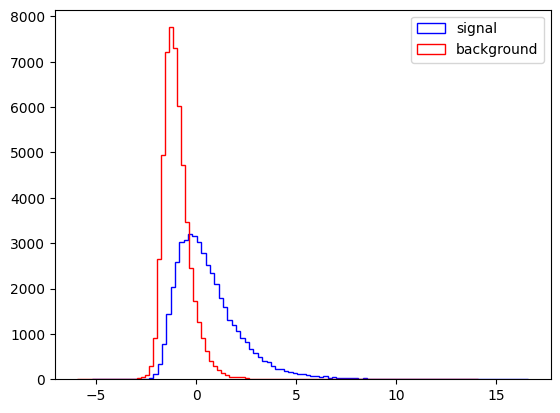

In [16]:
plt.figure()
plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]),bins=100,histtype="step", color="blue", label="signal",stacked=True)
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]),bins=100,histtype="step", color="red", label="background",stacked=True)
plt.legend(loc='upper right')
plt.show()

#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

In [19]:
from sklearn.metrics import roc_curve, auc

fpr_train, tpr_train, _ = roc_curve(
    y_Train, Fisher.decision_function(X_Train)
)

auc_train = auc(fpr_train, tpr_train)

fpr_test, tpr_test, _ = roc_curve(
    y_Test, Fisher.decision_function(X_Test)
)

auc_test = auc(fpr_test, tpr_test)

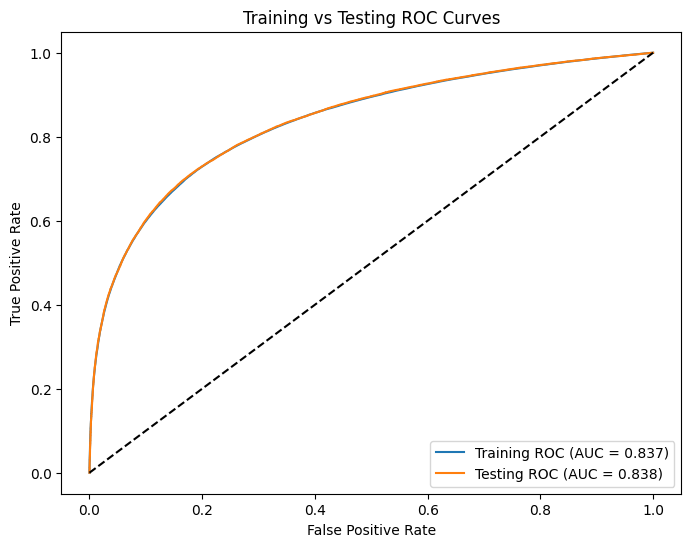

In [20]:
plt.figure(figsize=(8,6))

plt.plot(fpr_train, tpr_train,
         label='Training ROC (AUC = %.3f)' % auc_train)

plt.plot(fpr_test, tpr_test,
         label='Testing ROC (AUC = %.3f)' % auc_test)

plt.plot([0,1], [0,1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Training vs Testing ROC Curves')

plt.legend(loc='lower right')
plt.show()

The training and testing ROC are nearly identical, training ROC has an AUC of 0.837, while testing ROC has an AUC of 0.838. This shows that the classfier were consistent across both datasets, and there is no clear bias.

#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

In [23]:
Fisher_Raw = DA.LinearDiscriminantAnalysis()
Fisher_Features = DA.LinearDiscriminantAnalysis()
Fisher_All = DA.LinearDiscriminantAnalysis()

Fisher_Raw.fit(X_Train[RawNames], y_Train)

Fisher_Features.fit(X_Train[FeatureNames], y_Train)

Fisher_All.fit(X_Train[VarNames[1:]], y_Train)

fpr_raw, tpr_raw, _ = roc_curve(
    y_Test, Fisher_Raw.decision_function(X_Test[RawNames])
)

fpr_features, tpr_features, _ = roc_curve(
    y_Test, Fisher_Features.decision_function(X_Test[FeatureNames])
)

fpr_all, tpr_all, _ = roc_curve(
    y_Test, Fisher_All.decision_function(X_Test[VarNames[1:]])
)

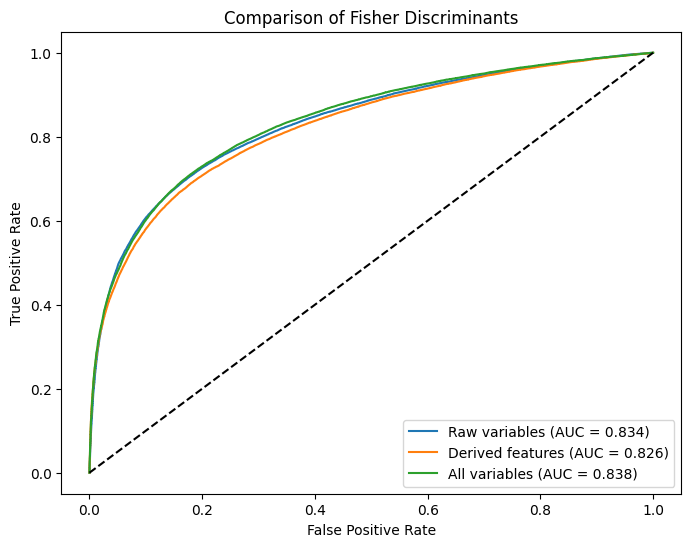

In [26]:

plt.figure(figsize=(8,6))

plt.plot(fpr_raw, tpr_raw,
         label='Raw variables (AUC = %.3f)' % auc_raw)

plt.plot(fpr_features, tpr_features,
         label='Derived features (AUC = %.3f)' % auc_features)

plt.plot(fpr_all, tpr_all,
         label='All variables (AUC = %.3f)' % auc_all)

plt.plot([0,1], [0,1], 'k--')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Comparison of Fisher Discriminants')

plt.legend(loc='lower right')
plt.show()

The classifier that had all 18 variables had an AUC of 0.838, while the classifer that only used raw variables had an AUC of 0.834, and the one with derived features had an AUC of 0.838. This shows that combining both variables resulted in a slightly better performance.

### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

Logistic = LogisticRegression(max_iter=1000)

SVM = LinearSVC(max_iter=5000, random_state=42)

Tree = DecisionTreeClassifier(random_state=42)

In [37]:
from sklearn.metrics import roc_curve, auc
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def compare_classifier(classifier, name):

    datasets = {
        "Raw variables": RawNames,
        "Derived features": FeatureNames,
        "All variables": VarNames[1:]
    }

    results = {}

    plt.figure(figsize=(8,6))

    for label, features in datasets.items():

        model = make_pipeline(
            StandardScaler(),
            clone(classifier)
        )

        model.fit(X_Train[features], y_Train)

        if hasattr(classifier, "predict_proba"):
          scores = model.predict_proba(X_Test[features])[:, 1]
        else:
          scores = model.decision_function(X_Test[features])

        fpr, tpr, thresholds = roc_curve(y_Test, scores)

        roc_auc = auc(fpr, tpr)

        results[label] = roc_auc

        plt.plot(
            fpr, tpr,
            label=f'{label} (AUC = {roc_auc:.3f})'
        )

    plt.plot([0,1], [0,1], 'k--')

    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(name + ' - ROC Comparison')

    plt.legend(loc='lower right')
    plt.show()

    print(name, "AUC Results:")
    for label, score in results.items():
        print(label, ":", round(score, 4))

    return results

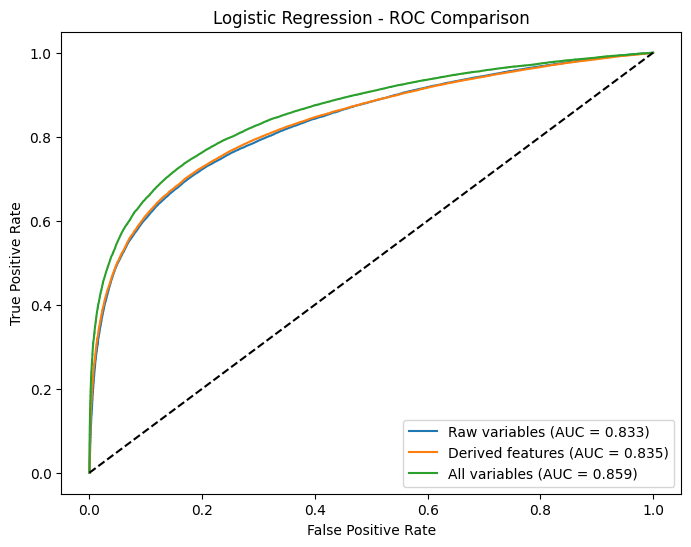

Logistic Regression AUC Results:
Raw variables : 0.8327
Derived features : 0.8349
All variables : 0.8588


In [30]:
Logistic_Results = compare_classifier(
    Logistic, "Logistic Regression"
)

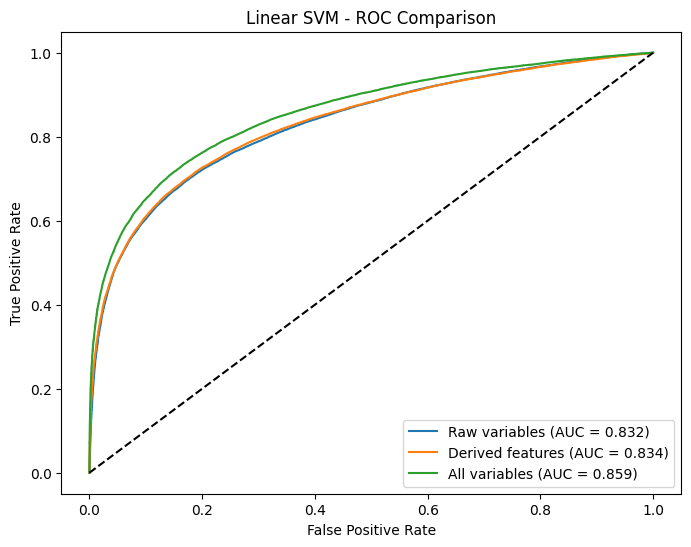

Linear SVM AUC Results:
Raw variables : 0.8321
Derived features : 0.8344
All variables : 0.8585


In [31]:
SVM_Results = compare_classifier(
    SVM, "Linear SVM"
)

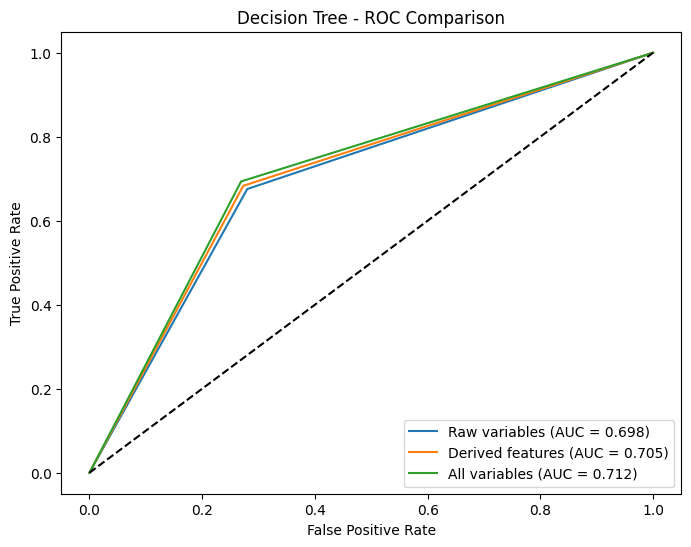

Decision Tree AUC Results:
Raw variables : 0.6978
Derived features : 0.7051
All variables : 0.7123


In [38]:
Tree_Results = compare_classifier(
    Tree, "Decision Tree"
)

,Scenario,NS,NB,Best Threshold,Signal Efficiency,Background Efficiency,Maximum Significance
0,1,10,100,1.3481,0.455,0.0243,1.7224
1,2,100,1000,1.3481,0.455,0.0243,5.4467
2,3,1000,10000,1.3481,0.455,0.0243,17.2240
3,4,10000,100000,1.3481,0.455,0.0243,54.4670


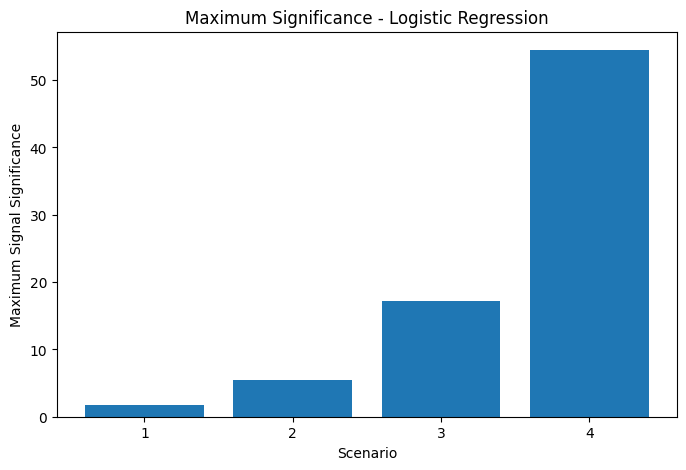

In [39]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


AllNames = RawNames + FeatureNames


Logistic_Best = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

Logistic_Best.fit(X_Train[AllNames], y_Train)


scores = Logistic_Best.decision_function(X_Test[AllNames])

y_test = np.asarray(y_Test)


signal_scores = scores[y_test == 1]
background_scores = scores[y_test == 0]


scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]


thresholds = np.concatenate((
    [-np.inf],
    np.unique(scores),
    [np.inf]
))

results = []

for i, (NS, NB) in enumerate(scenarios, 1):

    best_significance = 0
    best_threshold = None

    for cut in thresholds:


        eps_S = np.mean(signal_scores >= cut)
        eps_B = np.mean(background_scores >= cut)


        NS_prime = NS * eps_S
        NB_prime = NB * eps_B


        if NS_prime + NB_prime > 0:
            significance = NS_prime / np.sqrt(
                NS_prime + NB_prime
            )
        else:
            significance = 0

        if significance > best_significance:
            best_significance = significance
            best_threshold = cut
            best_eps_S = eps_S
            best_eps_B = eps_B

    results.append({
        "Scenario": i,
        "NS": NS,
        "NB": NB,
        "Best Threshold": best_threshold,
        "Signal Efficiency": best_eps_S,
        "Background Efficiency": best_eps_B,
        "Maximum Significance": best_significance
    })


results_df = pd.DataFrame(results)
display(results_df.round(4))


plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Scenario"].astype(str),
    results_df["Maximum Significance"]
)

plt.xlabel("Scenario")
plt.ylabel("Maximum Signal Significance")
plt.title("Maximum Significance - Logistic Regression")
plt.show()

# Used LLM to help me use the Lab 7 scenarios and incorporate them here.

### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

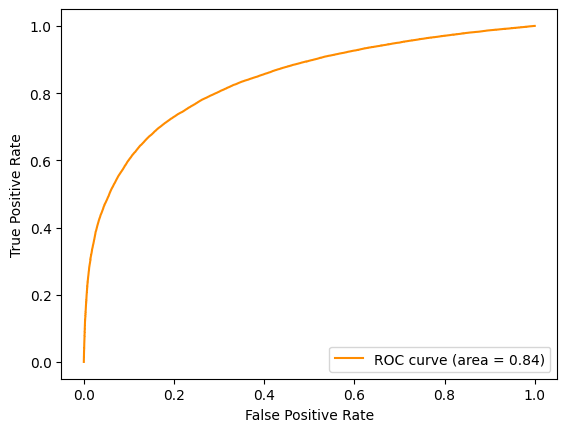

In [40]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()



#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance.


Logistic Regression - Exercise 5b Results
Best Threshold: 1.3481


,Scenario,NS,NB,TPR,FPR,AUC,Precision,Recall,F1 Score,Accuracy,Max Significance
0,1,10,100,0.4549,0.0243,0.8588,0.652,0.4549,0.536,0.9284,1.7223
1,2,100,1000,0.4549,0.0243,0.8588,0.652,0.4549,0.536,0.9284,5.4465
2,3,1000,10000,0.4549,0.0243,0.8588,0.652,0.4549,0.536,0.9284,17.2234
3,4,10000,100000,0.4549,0.0243,0.8588,0.652,0.4549,0.536,0.9284,54.4653


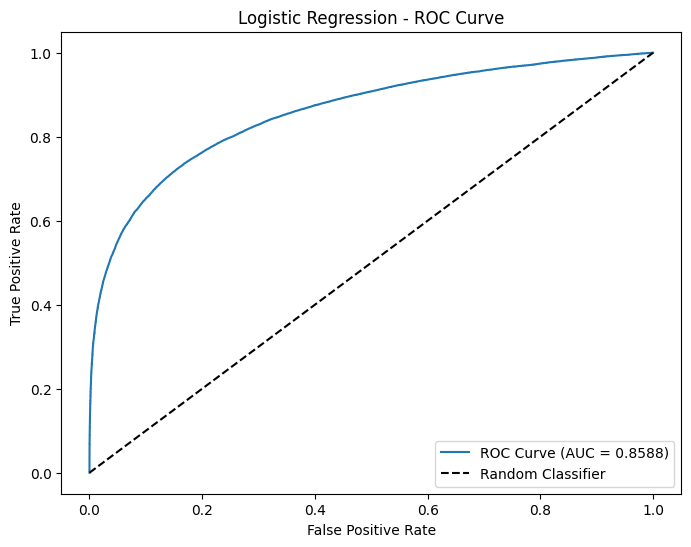

In [41]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve, auc, confusion_matrix,
    precision_score, recall_score,
    f1_score, accuracy_score
)

y_test = np.asarray(y_Test)
scores = Logistic_Best.decision_function(X_Test[AllNames])

best_threshold = 1.3481

fpr_curve, tpr_curve, thresholds = roc_curve(y_test, scores)
roc_auc = auc(fpr_curve, tpr_curve)

y_pred = (scores >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

tpr = tp / (tp + fn)
fpr = fp / (fp + tn)

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
accuracy = accuracy_score(y_test, y_pred)

scenarios = [
    (1, 10, 100),
    (2, 100, 1000),
    (3, 1000, 10000),
    (4, 10000, 100000)
]

results = []

for scenario, NS, NB in scenarios:

    NS_prime = NS * tpr
    NB_prime = NB * fpr

    significance = NS_prime / np.sqrt(NS_prime + NB_prime)

    scenario_precision = (
        NS_prime / (NS_prime + NB_prime)
        if NS_prime + NB_prime > 0 else 0
    )

    scenario_recall = tpr

    scenario_f1 = (
        2 * scenario_precision * scenario_recall /
        (scenario_precision + scenario_recall)
        if scenario_precision + scenario_recall > 0 else 0
    )

    scenario_accuracy = (
        (NS_prime + (NB - NB_prime)) / (NS + NB)
    )

    results.append({
        "Scenario": scenario,
        "NS": NS,
        "NB": NB,
        "TPR": tpr,
        "FPR": fpr,
        "AUC": roc_auc,
        "Precision": scenario_precision,
        "Recall": scenario_recall,
        "F1 Score": scenario_f1,
        "Accuracy": scenario_accuracy,
        "Max Significance": significance
    })

results_df = pd.DataFrame(results)

print("Logistic Regression - Exercise 5b Results")
print("Best Threshold:", best_threshold)

display(results_df.round(4))

plt.figure(figsize=(8, 6))
plt.plot(fpr_curve, tpr_curve,
         label=f'ROC Curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Logistic Regression - ROC Curve')
plt.legend(loc='lower right')
plt.show()

# Used LLM here to help the beginning of this cell, as starting it was complicated for me